# Wasserstein GANs

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'
plt.rcParams['axes.grid'] = True
plt.rcParams['axes.axisbelow'] = True
plt.rcParams['figure.dpi'] = 150

In [2]:
# Check available hardware
import torch
if torch.cuda.is_available():
    print(f'GPU is available, using GPU {torch.cuda.get_device_name(0)}')
    device = torch.device('cuda')
elif torch.mps.is_available():
    print(f'Apple Metal Performance Shaders framework is available, using {torch.device("mps")}')
    device = torch.device('mps')
else:
    print(f'Hardware acceleration not available, using CPU')
    device = torch.device('cpu')

GPU is available, using GPU Tesla T4


## Dataset: MNIST

In [3]:
import torch
import torchvision
from torchvision.transforms import v2

transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=(0.5,), std=(0.5,))
])
mnist_train = torchvision.datasets.MNIST(root='~/scr10/', train=True, transform=transform, download=True)
mnist_test = torchvision.datasets.MNIST(root='~/scr10/', train=False, transform=transform, download=False)
print('Training dataset has length', len(mnist_train))
print('Testing dataset has length', len(mnist_test))

Training dataset has length 60000
Testing dataset has length 10000


In [4]:
x, y = mnist_train[0]
print('Input has shape', x.shape, 'and the output is', y)

Input has shape torch.Size([1, 28, 28]) and the output is 5


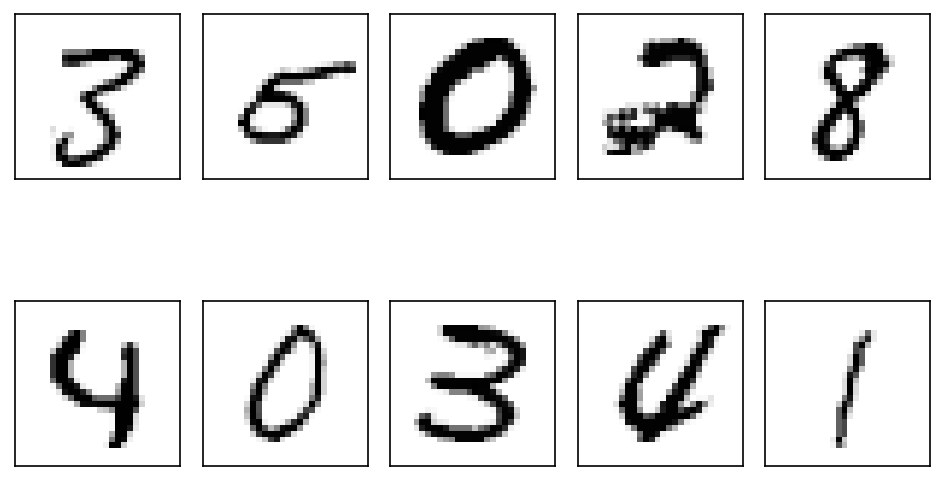

In [5]:
fig, ax = plt.subplots(2, 5, sharex=True, sharey=True)
ax = ax.flatten()
for ii in range(10):
    x, y = mnist_train[np.random.choice(len(mnist_train))]
    ax[ii].imshow(x.squeeze(), cmap='Greys')
    ax[ii].set(xticks=[], yticks=[])
plt.tight_layout()

## WGAN Implementation

In [6]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class Generator(nn.Module):
    def __init__(self, latent_size=10, hidden_size=128, output_size=28):
        super().__init__()

        # Going from [B, L, 1, 1] to [B, 1, 28, 28]
        self.generator = nn.Sequential(
            # [B, L, 1, 1]
            nn.ConvTranspose2d(latent_size, hidden_size, kernel_size=4, stride=1, padding=0),
            nn.BatchNorm2d(hidden_size),
            nn.LeakyReLU(0.2),
            # [B, H, 4, 4]
            nn.ConvTranspose2d(hidden_size, hidden_size, kernel_size=4, stride=1, padding=0),
            nn.BatchNorm2d(hidden_size),
            nn.LeakyReLU(0.2),
            # [B, H, 7, 7]
            nn.ConvTranspose2d(hidden_size, hidden_size, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(hidden_size),
            nn.LeakyReLU(0.2),
            # [B, H, 14, 14]
            nn.ConvTranspose2d(hidden_size, 1, kernel_size=4, stride=2, padding=1),
            nn.Tanh(),
        )
        self.output_size = output_size
        self.latent_size = latent_size

    def forward(self, z):
        z = z.reshape([z.shape[0], self.latent_size, 1, 1])
        x = self.generator(z)
        return x

class Discriminator(nn.Module):
    """ We consider the WGAN Critic/Discriminator as the best 
        possible K-Lipschitz function that maps images to real numbers
        1. "Best possible" means we train the discriminator to optimality
        2. "K-Lipschitz" means that the distance between two discriminator
            outputs is bounded by K x the distance between the inputs
    """
    def __init__(self, input_size=28, hidden_size=128):
        super().__init__()
        # Go from [B, 1, 28, 28] to #[B, 1, 1, 1]
        self.discriminator = nn.Sequential(
            # [B, 1, 28, 28],
            nn.Conv2d(1, hidden_size, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(hidden_size),
            nn.LeakyReLU(0.2),
            nn.Dropout(p=0.2),
            # [B, H, 14, 14],
            nn.Conv2d(hidden_size, hidden_size, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(hidden_size),
            nn.LeakyReLU(0.2),
            nn.Dropout(p=0.2),
            # [B, H, 7, 7],
            nn.Conv2d(hidden_size, hidden_size, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(hidden_size),
            nn.LeakyReLU(0.2),
            nn.Dropout(p=0.2),
            # [B, H, 3, 3],
            nn.Conv2d(hidden_size, 1, kernel_size=3, stride=1, padding=0),
        )

    def forward(self, x):
        y = self.discriminator(x)
        return y.reshape([y.shape[0], 1])

def sample_noise(shape, mode='uniform'):
    if mode == 'uniform':
        return 2 * torch.rand(*shape) - 1
    else:
        return torch.randn(*shape)

generator = Generator().to(device)
discriminator = Discriminator().to(device)

x_real, _ = mnist_train[0]
x_real = x_real[None].to(device)
print(x_real.shape)

z = sample_noise([1, generator.latent_size]).to(device)
print(z.shape)

x_fake = generator(z)
print(x_fake.shape)

y_real = discriminator(x_real)
y_fake = discriminator(x_fake)

print()
print(f'D(real) = {y_real.item():.3f}')
print(f'D(fake) = {y_fake.item():.3f}')

torch.Size([1, 1, 28, 28])
torch.Size([1, 10])
torch.Size([1, 1, 28, 28])

D(real) = -1.159
D(fake) = -0.579


In [7]:
def train_discriminator(x_real, generator, discriminator, optimizer, grad_clip=0.01):
    b = x_real.shape[0]
    discriminator.zero_grad()

    # Evaluate discriminator on true samples
    y_real = discriminator(x_real)
    loss_real = -y_real.mean()

    # Generate fake samples
    z_fake = sample_noise([b, generator.latent_size]).to(x_real.device)
    x_fake = generator(z_fake)

    # Evaluate discriminator on fake samples
    y_fake = discriminator(x_fake)

    # Total loss
    loss = -y_real.mean() + y_fake.mean()

    # Enforce K-Lipschitz constraint with gradient clipping
    torch.nn.utils.clip_grad_norm_(discriminator.parameters(), grad_clip)
    loss.backward()
    optimizer.step()

    return loss.item(), y_real.detach().cpu().numpy(), y_fake.detach().cpu().numpy()

def train_generator(x_real, generator, discriminator, optimizer):
    b = x_real.shape[0]
    generator.zero_grad()

    # Generate fake samples
    z_fake = sample_noise([b, generator.latent_size]).to(x_real.device)
    x_fake = generator(z_fake)

    # Evaluate discriminator on fake samples
    y_fake = discriminator(x_fake)

    loss = -y_fake.mean() # Fool the discriminator
    loss.backward()
    optimizer.step()
    
    return loss.item()

In [8]:
import os
from torch.utils.data import DataLoader
from tqdm import tqdm

def train_wgan(generator, 
               discriminator,
               opt_generator,
               opt_discriminator,
               dataset, 
               n_critic=5,
               batch_size=32, 
               num_epochs=100, 
               num_workers=0, 
               device=device,
               save_epochs=10,
               save_path='~/scr10/GAN'):
    # Send model to correct hardware device
    generator = generator.to(device)    
    discriminator = discriminator.to(device)    

    # Create dataloaders for train/validation
    loader = DataLoader(dataset, batch_size=batch_size, num_workers=num_workers, shuffle=True)

    logging = {
        'dis_loss': [],
        'gen_loss': [],
        'D(real)': [],
        'D(fake)': []
    }

    os.makedirs(os.path.expanduser(save_path), exist_ok=True)
    
    for epoch in range(num_epochs):
        # Prepare logging
        for key in logging:
            logging[key].append(0)
            
        for batch in tqdm(loader, leave=False):
            # Send x, y to GPU/TPU/etc.
            x = batch[0].float().to(device)

            # Train discriminator to "optimality"
            for _ in range(n_critic):
                dis_loss, y_real, y_fake = train_discriminator(x, generator, discriminator, opt_discriminator)

            # Train the generator
            gen_loss = train_generator(x, generator, discriminator, opt_generator)

            # Logging
            logging['dis_loss'][-1] += dis_loss * x.shape[0]
            logging['gen_loss'][-1] += gen_loss * x.shape[0]
            logging['D(real)'][-1] += y_real.sum()
            logging['D(fake)'][-1] += y_fake.sum()

        outstr = f'Epoch {epoch+1} | '
        for key in logging.keys():
            logging[key][-1] = logging[key][-1] / len(dataset)
            outstr += f'{key} {logging[key][-1]:.3f} | '

        print(outstr)

        if epoch % save_epochs == 0:
            torch.save({
                'generator_weights': generator.state_dict(),
                'discriminator_weights': discriminator.state_dict(),
                **logging,
                
            }, os.path.join(os.path.expanduser(save_path), f'MNIST_WGAN_epoch={epoch:03d}.pt'))

    return logging

In [9]:
torch.manual_seed(42)
generator = Generator()
discriminator = Discriminator()

opt_generator = torch.optim.RMSprop(generator.parameters(), lr=5e-5)
opt_discriminator = torch.optim.RMSprop(discriminator.parameters(), lr=5e-5)

logging = train_wgan(
    generator, discriminator,
    opt_generator, opt_discriminator,
    mnist_train, 
    device=device, 
    n_critic=5,
    batch_size=128, 
    num_epochs=1, 
    num_workers=4,
)

Epoch 1 | dis_loss -67.573 | gen_loss 34.568 | D(real) 34.517 | D(fake) -33.056 | 


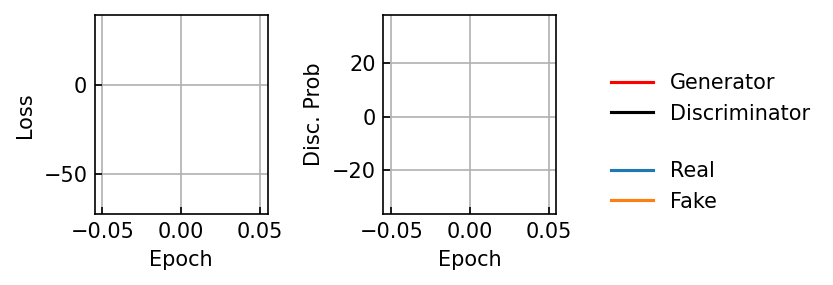

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(4, 2))

ax[0].plot(logging['gen_loss'], color='red', label='Generator')
ax[0].plot(logging['dis_loss'], color='black', label='Discriminator')
ax[0].set(xlabel='Epoch', ylabel='Loss')

ax[1].plot(logging['D(real)'], label='Real')
ax[1].plot(logging['D(fake)'], label='Fake')
ax[1].set(xlabel='Epoch', ylabel='Disc. Prob')
plt.tight_layout()

fig.legend(*ax[0].get_legend_handles_labels(), loc='lower left', bbox_to_anchor=[1, 0.5], framealpha=0)
fig.legend(*ax[1].get_legend_handles_labels(), loc='upper left', bbox_to_anchor=[1, 0.5], framealpha=0)

### Generate some fake samples

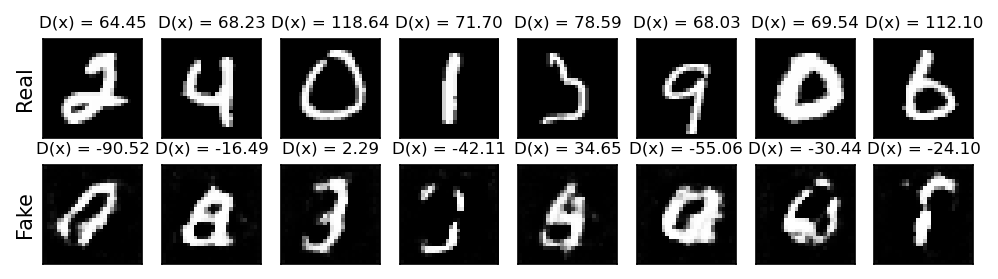

In [11]:
def real_vs_fake_plot(generator, discriminator, dataset, N=8):
    fig, ax = plt.subplots(2, N, figsize=(N, 2))
    with torch.no_grad():
        z_fake = sample_noise([N, generator.latent_size]).to(device)
        x_fake = generator(z_fake)

        idxs = np.random.choice(len(dataset), N)
        x_real = torch.concat([dataset[idx][0] for idx in idxs]).to(device)
        x_real = x_real.reshape(x_fake.shape)

        y_real = discriminator(x_real).cpu().numpy()[..., 0]
        y_fake = discriminator(x_fake).cpu().numpy()[..., 0]
        x_fake = x_fake.cpu().numpy()

    for ii in range(N):
        x_real = dataset[np.random.choice(len(dataset))][0]
        ax[0, ii].imshow(x_real[0], cmap='Greys_r', vmin=-1, vmax=1)
        ax[1, ii].imshow(x_fake[ii, 0], cmap='Greys_r', vmin=-1, vmax=1)

        ax[0, ii].set_title(f'D(x) = {y_real[ii]:.2f}', fontsize=8)
        ax[1, ii].set_title(f'D(x) = {y_fake[ii]:.2f}', fontsize=8)
    
    
    ax[0, 0].set_ylabel('Real')
    ax[1, 0].set_ylabel('Fake')
    
    for a in ax.flatten():
        a.set(xticks=[], yticks=[])
        a.grid(False)

real_vs_fake_plot(generator, discriminator, mnist_test)

## Improving WGAN with Gradient Penalty

In [12]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class Generator(nn.Module):
    def __init__(self, latent_size=10, hidden_size=128, output_size=28):
        super().__init__()

        # Going from [B, L, 1, 1] to [B, 1, 28, 28]
        self.generator = nn.Sequential(
            # [B, L, 1, 1]
            nn.ConvTranspose2d(latent_size, hidden_size, kernel_size=4, stride=1, padding=0),
            nn.LeakyReLU(0.2),
            # [B, H, 4, 4]
            nn.ConvTranspose2d(hidden_size, hidden_size, kernel_size=4, stride=1, padding=0),
            nn.LeakyReLU(0.2),
            # [B, H, 7, 7]
            nn.ConvTranspose2d(hidden_size, hidden_size, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2),
            # [B, H, 14, 14]
            nn.ConvTranspose2d(hidden_size, 1, kernel_size=4, stride=2, padding=1),
            nn.Tanh(),
        )
        self.output_size = output_size
        self.latent_size = latent_size

    def forward(self, z):
        z = z.reshape([z.shape[0], self.latent_size, 1, 1])
        x = self.generator(z)
        return x

class Discriminator(nn.Module):
    """ We consider the WGAN Critic/Discriminator as the best 
        possible K-Lipschitz function that maps images to real numbers
        1. "Best possible" means we train the discriminator to optimality
        2. "K-Lipschitz" means that the distance between two discriminator
            outputs is bounded by K x the distance between the inputs
    """
    def __init__(self, input_size=28, hidden_size=128):
        super().__init__()
        # Go from [B, 1, 28, 28] to #[B, 1, 1, 1]
        self.discriminator = nn.Sequential(
            # [B, 1, 28, 28],
            nn.Conv2d(1, hidden_size, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2),
            nn.Dropout(p=0.2),
            # [B, H, 14, 14],
            nn.Conv2d(hidden_size, hidden_size, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2),
            nn.Dropout(p=0.2),
            # [B, H, 7, 7],
            nn.Conv2d(hidden_size, hidden_size, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2),
            nn.Dropout(p=0.2),
            # [B, H, 3, 3],
            nn.Conv2d(hidden_size, 1, kernel_size=3, stride=1, padding=0),
        )

    def forward(self, x):
        y = self.discriminator(x)
        return y.reshape([y.shape[0], 1])

def sample_noise(shape, mode='uniform'):
    if mode == 'uniform':
        return 2 * torch.rand(*shape) - 1
    else:
        return torch.randn(*shape)

generator = Generator().to(device)
discriminator = Discriminator().to(device)

x_real, _ = mnist_train[0]
x_real = x_real[None].to(device)
print(x_real.shape)

z = sample_noise([1, generator.latent_size]).to(device)
print(z.shape)

x_fake = generator(z)
print(x_fake.shape)

y_real = discriminator(x_real)
y_fake = discriminator(x_fake)

print()
print(f'D(real) = {y_real.item():.3f}')
print(f'D(fake) = {y_fake.item():.3f}')

torch.Size([1, 1, 28, 28])
torch.Size([1, 10])
torch.Size([1, 1, 28, 28])

D(real) = 0.097
D(fake) = 0.054


In [13]:
def train_discriminator(x_real, generator, discriminator, optimizer, grad_lambda=10.):
    b = x_real.shape[0]
    discriminator.zero_grad()

    # Evaluate discriminator on true samples
    y_real = discriminator(x_real)
    loss_real = -y_real.mean()

    # Generate fake samples
    z_fake = sample_noise([b, generator.latent_size]).to(x_real.device)
    x_fake = generator(z_fake)

    # Evaluate discriminator on fake samples
    y_fake = discriminator(x_fake)

    # Total loss
    loss = -y_real.mean() + y_fake.mean()

    # Enforce K-Lipschitz constraint using gradient penalty

    # Interpolate between real and fake samples
    alpha = torch.rand(b, 1, 1, 1, dtype=torch.float, device=x_real.device, requires_grad=True)
    x_mid = alpha * x_real + (1 - alpha) * x_fake

    # Evaluate discriminator on these samples
    y_mid = discriminator(x_mid)

    # Get gradient of discriminator w.r.t. inputs
    gradient = torch.autograd.grad(
        inputs=x_mid,
        outputs=y_mid,
        grad_outputs=torch.ones_like(y_mid),
        create_graph=True,
        retain_graph=True
    )[0]
    gradient = gradient.reshape([b, -1])

    # Penalize the norm being unequal to 1
    grad_norm = gradient.norm(2, dim=1)
    grad_penalty = torch.mean((grad_norm - 1.) ** 2)

    loss = loss + grad_lambda * grad_penalty
    loss.backward()
    optimizer.step()

    return loss.item(), y_real.detach().cpu().numpy(), y_fake.detach().cpu().numpy()

In [14]:
torch.manual_seed(42)
generator = Generator()
discriminator = Discriminator()

opt_generator = torch.optim.Adam(generator.parameters(), lr=2e-4)
opt_discriminator = torch.optim.Adam(discriminator.parameters(), lr=2e-4)

logging = train_wgan(
    generator, discriminator,
    opt_generator, opt_discriminator,
    mnist_train, 
    device=device, 
    n_critic=5,
    batch_size=128, 
    num_epochs=1, 
    num_workers=4,
)

Epoch 1 | dis_loss -13.510 | gen_loss -1.436 | D(real) 18.333 | D(fake) 1.449 | 


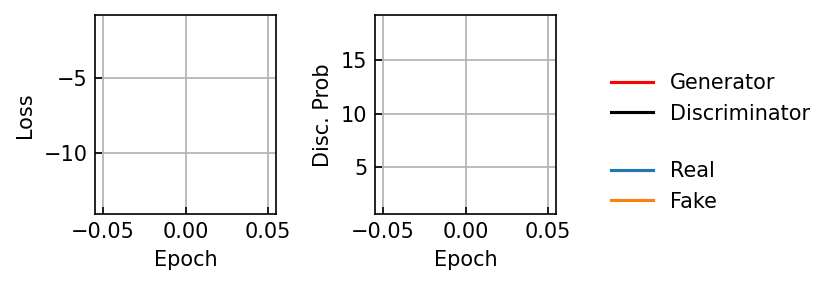

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(4, 2))

ax[0].plot(logging['gen_loss'], color='red', label='Generator')
ax[0].plot(logging['dis_loss'], color='black', label='Discriminator')
ax[0].set(xlabel='Epoch', ylabel='Loss')

ax[1].plot(logging['D(real)'], label='Real')
ax[1].plot(logging['D(fake)'], label='Fake')
ax[1].set(xlabel='Epoch', ylabel='Disc. Prob')
plt.tight_layout()

fig.legend(*ax[0].get_legend_handles_labels(), loc='lower left', bbox_to_anchor=[1, 0.5], framealpha=0)
fig.legend(*ax[1].get_legend_handles_labels(), loc='upper left', bbox_to_anchor=[1, 0.5], framealpha=0)

### Generate some fake samples

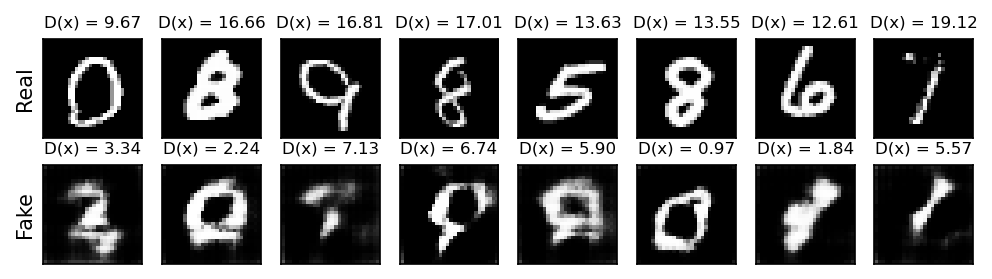

In [16]:
def real_vs_fake_plot(generator, discriminator, dataset, N=8):
    fig, ax = plt.subplots(2, N, figsize=(N, 2))
    with torch.no_grad():
        z_fake = sample_noise([N, generator.latent_size]).to(device)
        x_fake = generator(z_fake)

        idxs = np.random.choice(len(dataset), N)
        x_real = torch.concat([dataset[idx][0] for idx in idxs]).to(device)
        x_real = x_real.reshape(x_fake.shape)

        y_real = discriminator(x_real).cpu().numpy()[..., 0]
        y_fake = discriminator(x_fake).cpu().numpy()[..., 0]
        x_fake = x_fake.cpu().numpy()

    for ii in range(N):
        x_real = dataset[np.random.choice(len(dataset))][0]
        ax[0, ii].imshow(x_real[0], cmap='Greys_r', vmin=-1, vmax=1)
        ax[1, ii].imshow(x_fake[ii, 0], cmap='Greys_r', vmin=-1, vmax=1)

        ax[0, ii].set_title(f'D(x) = {y_real[ii]:.2f}', fontsize=8)
        ax[1, ii].set_title(f'D(x) = {y_fake[ii]:.2f}', fontsize=8)
    
    
    ax[0, 0].set_ylabel('Real')
    ax[1, 0].set_ylabel('Fake')
    
    for a in ax.flatten():
        a.set(xticks=[], yticks=[])
        a.grid(False)

real_vs_fake_plot(generator, discriminator, mnist_test)

In [17]:
generator

Generator(
  (generator): Sequential(
    (0): ConvTranspose2d(10, 128, kernel_size=(4, 4), stride=(1, 1))
    (1): LeakyReLU(negative_slope=0.2)
    (2): ConvTranspose2d(128, 128, kernel_size=(4, 4), stride=(1, 1))
    (3): LeakyReLU(negative_slope=0.2)
    (4): ConvTranspose2d(128, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (5): LeakyReLU(negative_slope=0.2)
    (6): ConvTranspose2d(128, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (7): Tanh()
  )
)

In [18]:
discriminator

Discriminator(
  (discriminator): Sequential(
    (0): Conv2d(1, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): LeakyReLU(negative_slope=0.2)
    (2): Dropout(p=0.2, inplace=False)
    (3): Conv2d(128, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (4): LeakyReLU(negative_slope=0.2)
    (5): Dropout(p=0.2, inplace=False)
    (6): Conv2d(128, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (7): LeakyReLU(negative_slope=0.2)
    (8): Dropout(p=0.2, inplace=False)
    (9): Conv2d(128, 1, kernel_size=(3, 3), stride=(1, 1))
  )
)